In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

In [2]:
data = pd.read_csv("/content/sample_data/diabetes.csv")

In [3]:
data.shape

(768, 9)

In [ ]:
data.head(5)

In [ ]:
# check if any null value is present
data.isnull().values.any()

In [ ]:
## Correlation
import seaborn as sns
import matplotlib.pyplot as plt
#get correlations of each features in dataset
corrmat = data.corr()
top_corr_features = corrmat.index
plt.figure(figsize=(20,20))
#plot heat map
g=sns.heatmap(data[top_corr_features].corr(),annot=True,cmap="RdYlGn")

In [ ]:
data.corr()

In [8]:
diabetes_true_count = len(data.loc[data['Outcome'] == 1])
diabetes_false_count = len(data.loc[data['Outcome'] == 0])

In [9]:
(diabetes_true_count,diabetes_false_count)

(268, 500)

In [10]:
X = data.drop('Outcome', axis=1)
y = data['Outcome']

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state=10)

In [ ]:
#Missing (Zero) rows
print("total number of rows : {0}".format(len(data)))
print("number of rows missing glucose_conc: {0}".format(len(data.loc[data['Glucose'] == 0])))
print("number of rows missing glucose_conc: {0}".format(len(data.loc[data['BloodPressure'] == 0])))
print("number of rows missing diastolic_bp: {0}".format(len(data.loc[data['SkinThickness'] == 0])))
print("number of rows missing insulin: {0}".format(len(data.loc[data['Insulin'] == 0])))
print("number of rows missing bmi: {0}".format(len(data.loc[data['BMI'] == 0])))
print("number of rows missing diab_pred: {0}".format(len(data.loc[data['DiabetesPedigreeFunction'] == 0])))
print("number of rows missing age: {0}".format(len(data.loc[data['Age'] == 0])))

In [13]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=0, strategy='mean')

#fill_values = Imputer(missing_values=0, strategy="mean", axis=0)

X_train = imputer.fit_transform(X_train)
X_test = imputer.fit_transform(X_test)

In [ ]:
from sklearn import linear_model
LR=linear_model.LogisticRegression().fit(X_train, y_train)

print(LR.score(X_test, y_test))

In [ ]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

clf.fit(X_train,y_train)

pred_train = clf.predict(X_train)
pred_test = clf.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy_train = accuracy_score(pred_train,y_train)
accuracy_test = accuracy_score(pred_test,y_test)

from sklearn import metrics
fpr, tpr, _ = metrics.roc_curve(np.array(y_train), clf.predict_proba(X_train)[:,1])
auc_train = metrics.auc(fpr,tpr)

fpr, tpr, _ = metrics.roc_curve(np.array(y_test), clf.predict_proba(X_test)[:,1])
auc_test = metrics.auc(fpr,tpr)

print(accuracy_train,accuracy_test,auc_train,auc_test)
pd.crosstab(y_train,pd.Series(pred_train),rownames=['ACTUAL'],colnames=['PRED'])
pd.crosstab(y_test,pd.Series(pred_test),rownames=['ACTUAL'],colnames=['PRED'])

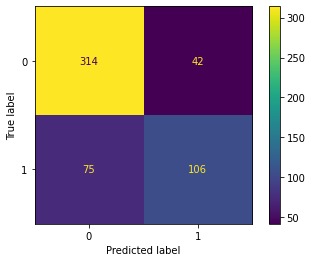

In [17]:
metrics.plot_confusion_matrix(clf, X_train,y_train,values_format='d')